# 04 · Previsão 2026–2035

Como transformar padrões históricos em uma resposta defensável para os próximos 10 anos?
Seguimos quatro princípios:

1. **Nenhum modelo é escolhido por gosto.** Todos passam por *backtesting* com origem móvel: fingimos estar em
   2003, 2004, …, 2015, prevemos 10 anos à frente e comparamos com o que realmente aconteceu.
2. **Ensemble ponderado pelo desempenho** fora da amostra, porque os modelos erram em direções diferentes.
3. **Incerteza explícita:** intervalos empíricos (a partir dos erros reais do backtest) e **Monte Carlo** com
   *block bootstrap* de 20.000 cenários.
4. **Triangulação** com um modelo estrutural e com a projeção oficial do **BLS 2025–2035**.

Série-alvo: emprego anual médio no núcleo tech dos EUA (1990–2025). 2026 ainda está incompleto e serve como
**checagem fora da amostra** (média jan–set).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from techdemand import data_sources as ds, features as ft, models as m, style

warnings.filterwarnings("ignore")
style.apply()
%matplotlib inline

panel = ds.fetch_fred_panel()
tech_m = ft.tech_employment(panel)
tech = ft.annual(tech_m)
total = ft.annual(panel["PAYEMS"])
ytd_2026 = tech_m.loc["2026"].mean()
H, ULTIMO = 10, tech.index[-1]
TECH = style.color_for("Núcleo tech")
print(f"Treino: {tech.index[0]}–{ULTIMO} ({len(tech)} anos) · 2026 parcial (jan–set): {style.fmt_num(ytd_2026)} mil")

Treino: 1990–2025 (36 anos) · 2026 parcial (jan–set): 2.829 mil


## 1. Backtesting com origem móvel

**Modelos candidatos**

| Modelo | Ideia |
|---|---|
| Ingênuo | o emprego fica parado: referência mínima a ser batida |
| Tendência robusta (Theil-Sen 15a) | crescimento log-linear dos últimos 15 anos, resistente a outliers |
| ETS amortecido | Holt com tendência que perde força ao longo do horizonte |
| ARIMA com drift | ordem (p,1,q) escolhida por AIC |
| Ensemble (pesos iguais) | média geométrica dos três modelos de tendência |

Origens de 2003 a 2015 (13 janelas). Origens anteriores ficam de fora da avaliação principal porque o treino seria
dominado pela hiperexpansão dos anos 1990, que não representa um setor maduro — a análise de sensibilidade
com todas as origens vem logo abaixo.

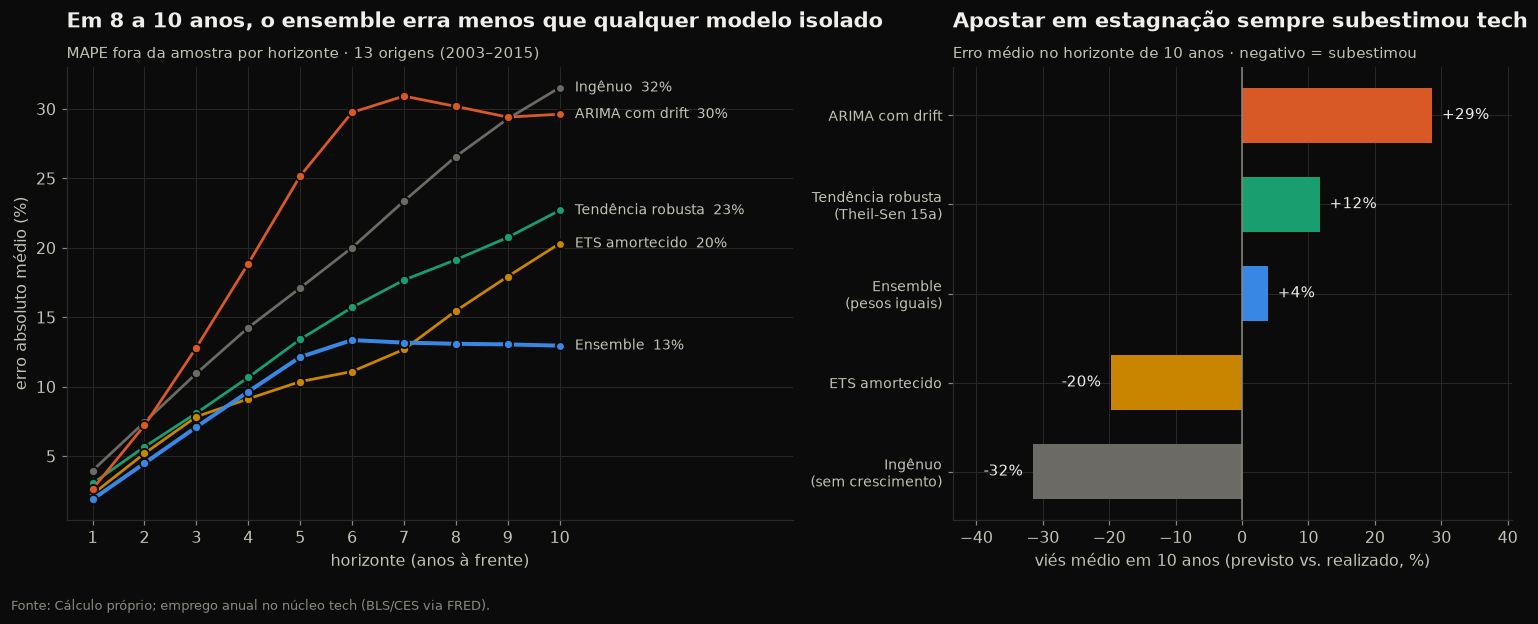

Modelo 'sem crescimento' subestimou o emprego 10 anos depois em 13 de 13 origens.


modelo,ARIMA com drift,ETS amortecido,Ensemble (pesos iguais),Ingênuo (sem crescimento),Tendência robusta (Theil-Sen 15a)
h,,,,,
1,2.6,2.3,1.9,4.0,3.0
3,12.8,7.8,7.1,11.0,8.1
5,25.2,10.4,12.1,17.1,13.4
10,29.6,20.3,13.0,31.5,22.7


In [2]:
candidatos = {**m.MODELS, "Ensemble (pesos iguais)": m.equal_weight_ensemble}
bt = m.backtest(tech, candidatos, origins=range(2003, 2016), h=H)
mape = bt.pivot_table(index="h", columns="modelo", values="ape", aggfunc="mean")
vies = bt[bt.h == H].groupby("modelo")["erro_pct"].mean()

cores_mod = {"Ingênuo (sem crescimento)": style.NEUTRAL, "Tendência robusta (Theil-Sen 15a)": style.PALETTE[2],
             "ETS amortecido": style.PALETTE[3], "ARIMA com drift": style.PALETTE[1],
             "Ensemble (pesos iguais)": TECH}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
for nome, cor in cores_mod.items():
    ax1.plot(mape.index, mape[nome], "o-", color=cor, ms=6, lw=2.6 if "Ensemble" in nome else 1.8,
             mec=style.SURFACE, mew=1.2)
    style.label_line_end(ax1, H, mape.loc[H, nome], f"{nome.split(' (')[0]}  {mape.loc[H, nome]:.0f}%", cor, dx=4)
ax1.set_xlim(0.5, 14.5)
ax1.set_xticks(range(1, 11))
ax1.set_xlabel("horizonte (anos à frente)")
ax1.set_ylabel("erro absoluto médio (%)")
ax1.set_title("Em 8 a 10 anos, o ensemble erra menos que qualquer modelo isolado")
style.subtitle(ax1, "MAPE fora da amostra por horizonte · 13 origens (2003–2015)")

ordem = vies.sort_values().index
ax2.barh(range(len(ordem)), vies[ordem], color=[cores_mod[n] for n in ordem], height=0.62)
ax2.axvline(0, color=style.TEXT_MUTED, lw=1)
for i, n in enumerate(ordem):
    v = vies[n]
    ax2.text(v + (1.5 if v >= 0 else -1.5), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right",
             fontsize=9.5, color=style.TEXT_PRIMARY)
ax2.set_yticks(range(len(ordem)), [n.replace(" (", "\n(") for n in ordem], fontsize=9)
ax2.set_xlim(vies.min() - 12, vies.max() + 12)
ax2.set_xlabel("viés médio em 10 anos (previsto vs. realizado, %)")
ax2.set_title("Apostar em estagnação sempre subestimou tech")
style.subtitle(ax2, "Erro médio no horizonte de 10 anos · negativo = subestimou")
style.source(fig, "Cálculo próprio; emprego anual no núcleo tech (BLS/CES via FRED).")
fig.tight_layout()
style.save(fig, "04_01_backtest")
plt.show()

ing = bt[(bt.modelo == "Ingênuo (sem crescimento)") & (bt.h == H)]
print(f"Modelo 'sem crescimento' subestimou o emprego 10 anos depois em {(ing.erro_pct < 0).sum()} de {len(ing)} origens.")
mape.loc[[1, 3, 5, 10]].round(1)

**Sensibilidade:** incluindo as origens 1998–2002 (treino contaminado pela bolha .com).

In [3]:
bt_all = m.backtest(tech, candidatos, origins=range(1998, 2016), h=H)
pd.DataFrame({
    "MAPE 10a (2003–2015)": bt[bt.h == H].groupby("modelo")["ape"].mean(),
    "MAPE 10a (1998–2015)": bt_all[bt_all.h == H].groupby("modelo")["ape"].mean(),
    "subestimou em 10a (% das origens) 1998–2015": bt_all[bt_all.h == H].groupby("modelo")["erro_pct"].apply(lambda e: (e < 0).mean() * 100),
}).round(1)

,MAPE 10a (2003–2015),MAPE 10a (1998–2015),subestimou em 10a (% das origens) 1998–2015
modelo,,,
ARIMA com drift,29.6,41.4,11.1
ETS amortecido,20.3,45.3,66.7
Ensemble (pesos iguais),13.0,34.0,33.3
Ingênuo (sem crescimento),31.5,27.2,100.0
Tendência robusta (Theil-Sen 15a),22.7,50.6,33.3


> Com as origens da bolha, os modelos de tendência pioram muito (extrapolam o crescimento de ~10% a.a. dos anos 90)
> e o ingênuo passa a ter MAPE menor — **mas continua errando sempre para baixo**. Isso reforça a conclusão: o
> risco de errar na direção de "tech vai encolher" foi, historicamente, o maior.

## 2. Previsão do ensemble ponderado

Pesos ∝ 1/MAPE nos horizontes de 5 a 10 anos. O intervalo de 80% vem dos quantis 10% e 90% dos erros reais
do ensemble no backtest (intervalo empírico, sem supor normalidade).

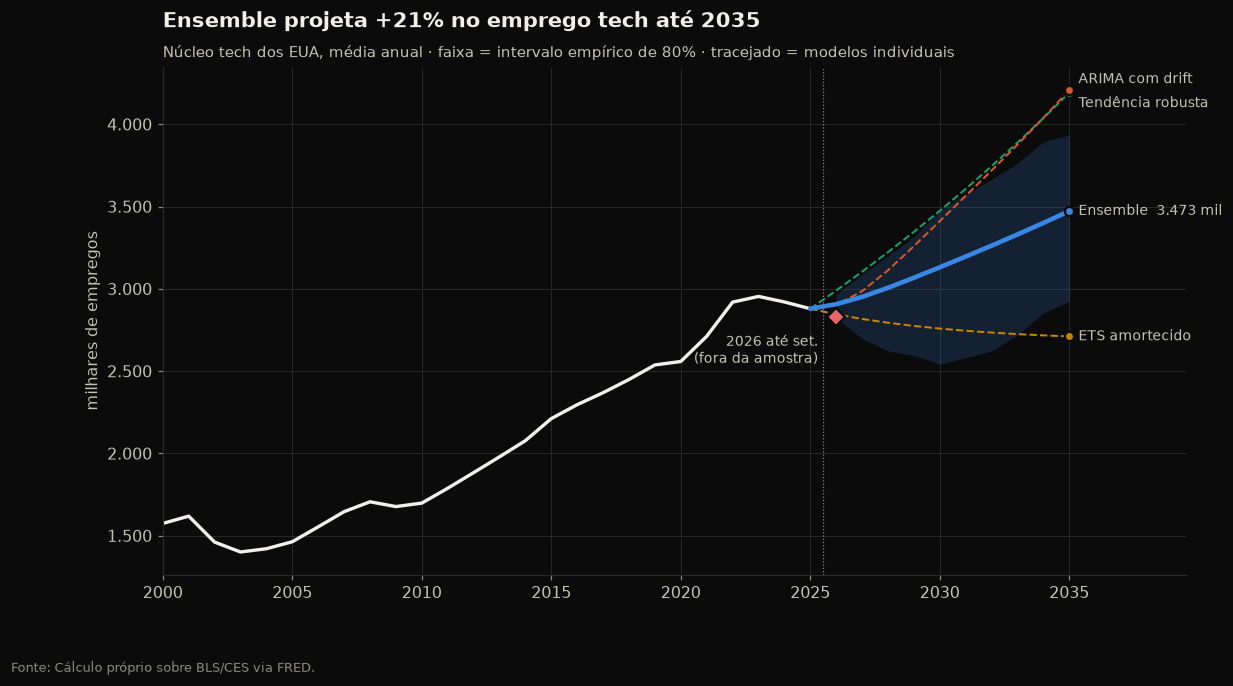

Pesos: {'ARIMA com drift': 21.8, 'ETS amortecido': 43.4, 'Tendência robusta (Theil-Sen 15a)': 34.8}
Checagem 2026: ensemble previu 2.907 mil · realizado (jan–set) 2.829 mil → erro +2.8%


,Ingênuo (sem crescimento),Tendência robusta (Theil-Sen 15a),ETS amortecido,ARIMA com drift,Ensemble,Ensemble inferior 80%,Ensemble superior 80%
year,,,,,,,
2026,2879.0,2990.0,2845.0,2901.0,2907.0,2824.0,2968.0
2030,2879.0,3474.0,2759.0,3412.0,3131.0,2542.0,3476.0
2035,2879.0,4192.0,2711.0,4208.0,3473.0,2925.0,3934.0


In [4]:
pesos = m.skill_weights(bt[bt.modelo != "Ensemble (pesos iguais)"])
previsoes = {nome: fn(tech, H) for nome, fn in m.MODELS.items()}
ens = m.ensemble(previsoes, pesos)
iv = m.empirical_interval(ens, bt[bt.modelo == "Ensemble (pesos iguais)"])

fig, ax = plt.subplots(figsize=(12, 6))
hist = tech.loc[2000:]
ax.plot(hist.index, hist, color=style.TEXT_PRIMARY, lw=2.2)
ax.fill_between(iv.index, iv["inferior"], iv["superior"], color=TECH, alpha=0.18, lw=0)
ponte = lambda s: pd.concat([tech.iloc[[-1]], s])
for nome, fc in previsoes.items():
    if nome.startswith("Ingênuo"):
        continue
    s = ponte(fc)
    ax.plot(s.index, s, color=cores_mod[nome], lw=1.3, ls="--")
    desloc = {"ARIMA com drift": 7, "Tendência robusta (Theil-Sen 15a)": -7}.get(nome, 0)
    style.label_line_end(ax, s.index[-1], s.iloc[-1], nome.split(" (")[0], cores_mod[nome], dy=desloc)
s = ponte(ens)
ax.plot(s.index, s, color=TECH, lw=3)
style.label_line_end(ax, s.index[-1], s.iloc[-1], f"Ensemble  {style.fmt_num(s.iloc[-1])} mil", TECH)
ax.plot(2026, ytd_2026, "D", color=style.PALETTE[7], ms=8, mec=style.SURFACE, mew=1.5, zorder=6)
ax.annotate("2026 até set.\n(fora da amostra)", (2026, ytd_2026), xytext=(-12, -30), textcoords="offset points",
            ha="right", fontsize=9, color=style.TEXT_SECONDARY)
ax.axvline(ULTIMO + 0.5, color=style.TEXT_MUTED, lw=0.8, ls=":")
ax.set_xlim(2000, 2039.5)
style.thousands_axis(ax)
ax.set_ylabel("milhares de empregos")
ax.set_title(f"Ensemble projeta {(ens.iloc[-1] / tech.iloc[-1] - 1) * 100:+.0f}% no emprego tech até 2035")
style.subtitle(ax, "Núcleo tech dos EUA, média anual · faixa = intervalo empírico de 80% · tracejado = modelos individuais")
style.source(fig, "Cálculo próprio sobre BLS/CES via FRED.")
style.save(fig, "04_02_previsao_ensemble")
plt.show()

tabela = pd.DataFrame({nome: fc for nome, fc in previsoes.items()}).assign(Ensemble=ens)
tabela["Ensemble inferior 80%"] = iv["inferior"]
tabela["Ensemble superior 80%"] = iv["superior"]
print("Pesos:", (pesos * 100).round(1).to_dict())
print(f"Checagem 2026: ensemble previu {style.fmt_num(ens.loc[2026])} mil · realizado (jan–set) {style.fmt_num(ytd_2026)} mil "
      f"→ erro {(ens.loc[2026] / ytd_2026 - 1) * 100:+.1f}%")
tabela.loc[[2026, 2030, 2035]].round(0)

## 3. Monte Carlo: 20.000 futuros possíveis

Em vez de um único número, simulamos 20.000 trajetórias reamostrando **blocos de 3 anos** de crescimento
histórico (2001–2025, o período pós-bolha, que inclui as crises de 2001–03, 2008–09, 2020 e 2023–25).
Blocos preservam o fato de que anos ruins vêm em sequência. O resultado responde diretamente à pergunta do projeto:
**qual a probabilidade de a demanda ser maior em 2035?**

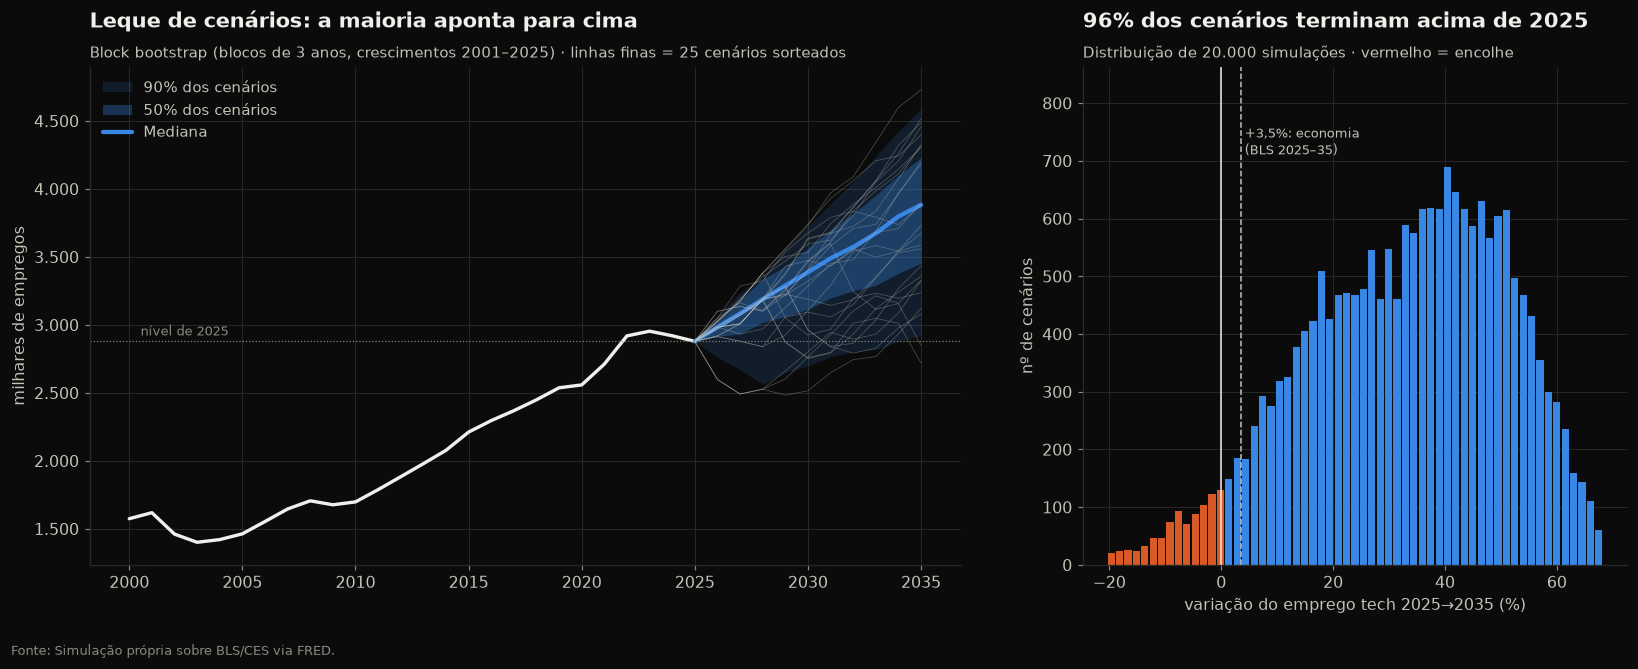

,Monte Carlo
P(emprego 2035 > 2025),95.5%
P(emprego 2035 > pico de 2022),94.3%
"P(crescer mais que a economia, +3,5%)",93.7%
Mediana da variação 10 anos,+34.9%
Intervalo de 90%,+1.4% a +59.4%


In [5]:
paths = m.block_bootstrap_paths(tech, h=H, n_sims=20_000, block=3, since=2001)
q = paths.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).T
final = paths[ULTIMO + H]
pico = tech.max()
p_up = (final > tech.iloc[-1]).mean()
p_peak = (final > pico).mean()
p_bls_total = (final / tech.iloc[-1] - 1 > 0.035).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(tech.loc[2000:].index, tech.loc[2000:], color=style.TEXT_PRIMARY, lw=2.2)
xs = [ULTIMO, *q.index]
banda = lambda col: [tech.iloc[-1], *q[col]]
ax1.fill_between(xs, banda(0.05), banda(0.95), color=TECH, alpha=0.15, lw=0, label="90% dos cenários")
ax1.fill_between(xs, banda(0.25), banda(0.75), color=TECH, alpha=0.32, lw=0, label="50% dos cenários")
ax1.plot(xs, banda(0.5), color=TECH, lw=2.8, label="Mediana")
rng = np.random.default_rng(7)
for i in rng.choice(len(paths), 25, replace=False):
    ax1.plot(xs, [tech.iloc[-1], *paths.iloc[i]], color=style.TEXT_SECONDARY, lw=0.5, alpha=0.35)
ax1.axhline(tech.iloc[-1], color=style.TEXT_MUTED, lw=0.8, ls=":")
ax1.text(2000.5, tech.iloc[-1] * 1.015, f"nível de {ULTIMO}", fontsize=8.5, color=style.TEXT_MUTED)
ax1.legend(loc="upper left")
style.thousands_axis(ax1)
ax1.set_ylabel("milhares de empregos")
ax1.set_title("Leque de cenários: a maioria aponta para cima")
style.subtitle(ax1, "Block bootstrap (blocos de 3 anos, crescimentos 2001–2025) · linhas finas = 25 cenários sorteados")

var = (final / tech.iloc[-1] - 1) * 100
bins = np.linspace(var.quantile(0.002), var.quantile(0.998), 60)
cnt, edges = np.histogram(var, bins=bins)
centros = (edges[:-1] + edges[1:]) / 2
ax2.bar(centros, cnt, width=(edges[1] - edges[0]) * 0.85,
        color=[style.DIVERGING[0] if c < 0 else TECH for c in centros])
ax2.axvline(0, color=style.TEXT_PRIMARY, lw=1)
ax2.axvline(3.5, color=style.TEXT_SECONDARY, lw=1, ls="--")
ax2.text(3.5, cnt.max() * 1.02, " +3,5%: economia\n (BLS 2025–35)", fontsize=8.5, color=style.TEXT_SECONDARY, va="bottom")
ax2.set_ylim(0, cnt.max() * 1.25)
ax2.set_xlabel(f"variação do emprego tech {ULTIMO}→{ULTIMO + H} (%)")
ax2.set_ylabel("nº de cenários")
ax2.set_title(f"{p_up * 100:.0f}% dos cenários terminam acima de {ULTIMO}")
style.subtitle(ax2, "Distribuição de 20.000 simulações · vermelho = encolhe")
style.source(fig, "Simulação própria sobre BLS/CES via FRED.")
fig.tight_layout()
style.save(fig, "04_03_monte_carlo")
plt.show()

pd.Series({
    f"P(emprego {ULTIMO + H} > {ULTIMO})": f"{p_up * 100:.1f}%",
    f"P(emprego {ULTIMO + H} > pico de 2022)": f"{p_peak * 100:.1f}%",
    "P(crescer mais que a economia, +3,5%)": f"{p_bls_total * 100:.1f}%",
    "Mediana da variação 10 anos": f"{var.median():+.1f}%",
    "Intervalo de 90%": f"{var.quantile(0.05):+.1f}% a {var.quantile(0.95):+.1f}%",
}, name="Monte Carlo").to_frame()

## 4. Modelo estrutural: participação × economia

Um modelo independente da extrapolação direta: projetamos a **participação** do tech no emprego total
(tendência Theil-Sen dos últimos 15 anos) e multiplicamos pelo emprego total crescendo **+3,5% em 10 anos**,
como projeta oficialmente o BLS para o conjunto da economia.

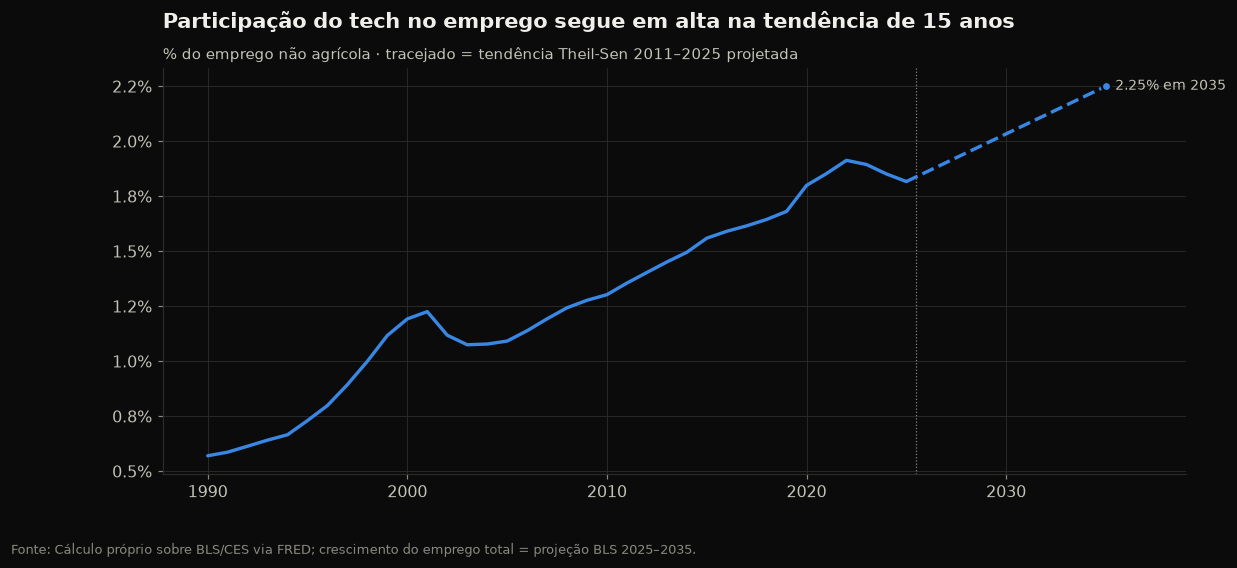

Modelo estrutural: 3.691 mil em 2035 (+28.2% vs 2025)


In [6]:
est = m.structural_share(tech, total, h=H, total_growth_h=0.035)
share_hist = tech / total * 100
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(share_hist.index, share_hist, color=TECH, lw=2.2)
ax.plot([ULTIMO, *est.index], [share_hist.iloc[-1], *(est["participacao"] * 100)], color=TECH, lw=2.2, ls="--")
style.label_line_end(ax, est.index[-1], est["participacao"].iloc[-1] * 100,
                     f"{est['participacao'].iloc[-1] * 100:.2f}% em {est.index[-1]}", TECH)
ax.axvline(ULTIMO + 0.5, color=style.TEXT_MUTED, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}%")
ax.set_xlim(right=2039)
ax.set_title("Participação do tech no emprego segue em alta na tendência de 15 anos")
style.subtitle(ax, "% do emprego não agrícola · tracejado = tendência Theil-Sen 2011–2025 projetada")
style.source(fig, "Cálculo próprio sobre BLS/CES via FRED; crescimento do emprego total = projeção BLS 2025–2035.")
style.save(fig, "04_04_modelo_estrutural")
plt.show()
print(f"Modelo estrutural: {style.fmt_num(est['tech'].iloc[-1])} mil em {est.index[-1]} "
      f"({(est['tech'].iloc[-1] / tech.iloc[-1] - 1) * 100:+.1f}% vs {ULTIMO})")

## 5. Triangulação: todos os métodos vs. projeção oficial do BLS

O BLS projeta **ocupações** (profissionais de computação em qualquer setor), enquanto nossos modelos projetam
**empresas do setor tech**. São recortes diferentes de um mesmo mercado — se convergirem na direção, a evidência é forte.

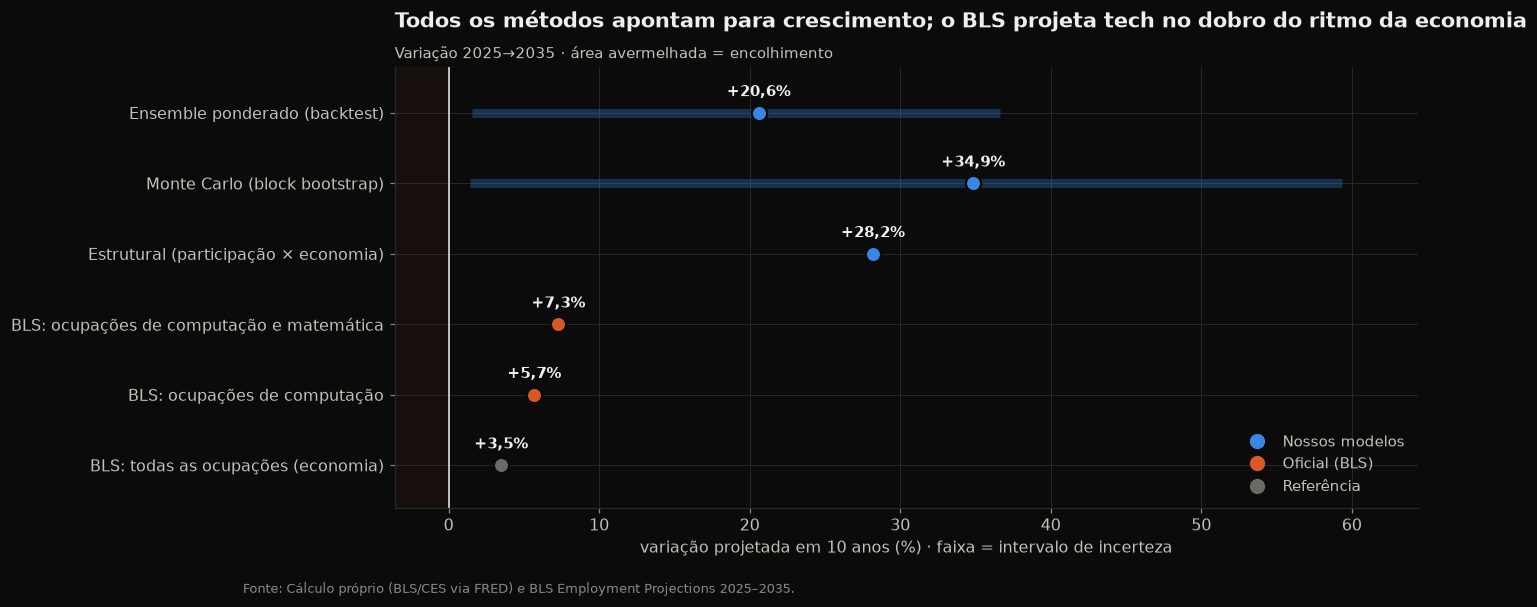

,método,central,inf,sup,tipo
0,Ensemble ponderado (backtest),20.6,1.6,36.6,Nossos modelos
1,Monte Carlo (block bootstrap),34.9,1.4,59.4,Nossos modelos
2,Estrutural (participação × economia),28.2,NaN,NaN,Nossos modelos
3,BLS: ocupações de computação e matemática,7.3,NaN,NaN,Oficial (BLS)
4,BLS: ocupações de computação,5.7,NaN,NaN,Oficial (BLS)
5,BLS: todas as ocupações (economia),3.5,NaN,NaN,Referência


In [7]:
bls = ds.load_bls_projections().set_index("soc_code")
g = lambda v: (v / tech.iloc[-1] - 1) * 100
metodos = pd.DataFrame([
    {"método": "Ensemble ponderado (backtest)", "central": g(ens.iloc[-1]),
     "inf": g(iv["inferior"].iloc[-1]), "sup": g(iv["superior"].iloc[-1]), "tipo": "Nossos modelos"},
    {"método": "Monte Carlo (block bootstrap)", "central": var.median(),
     "inf": var.quantile(0.05), "sup": var.quantile(0.95), "tipo": "Nossos modelos"},
    {"método": "Estrutural (participação × economia)", "central": g(est["tech"].iloc[-1]),
     "inf": np.nan, "sup": np.nan, "tipo": "Nossos modelos"},
    {"método": "BLS: ocupações de computação e matemática", "central": bls.loc["15-0000", "change_pct"],
     "inf": np.nan, "sup": np.nan, "tipo": "Oficial (BLS)"},
    {"método": "BLS: ocupações de computação", "central": bls.loc["15-1200", "change_pct"],
     "inf": np.nan, "sup": np.nan, "tipo": "Oficial (BLS)"},
    {"método": "BLS: todas as ocupações (economia)", "central": bls.loc["00-0000", "change_pct"],
     "inf": np.nan, "sup": np.nan, "tipo": "Referência"},
])

cor_tipo = {"Nossos modelos": TECH, "Oficial (BLS)": style.PALETTE[1], "Referência": style.NEUTRAL}
fig, ax = plt.subplots(figsize=(12, 5.2))
y = np.arange(len(metodos))[::-1]
for yi, (_, r) in zip(y, metodos.iterrows()):
    c = cor_tipo[r["tipo"]]
    if pd.notna(r["inf"]):
        ax.hlines(yi, r["inf"], r["sup"], color=c, lw=6, alpha=0.3)
    ax.plot(r["central"], yi, "o", color=c, ms=10, mec=style.SURFACE, mew=1.5, zorder=3)
    ax.annotate(("+" if r["central"] > 0 else "") + style.fmt_num(r["central"], 1) + "%", (r["central"], yi),
                xytext=(0, 11), textcoords="offset points",
                ha="center", fontsize=9.5, color=style.TEXT_PRIMARY, fontweight="bold")
ax.axvline(0, color=style.TEXT_PRIMARY, lw=1)
ax.axvspan(metodos["inf"].min() - 5, 0, color=style.DIVERGING[0], alpha=0.06, lw=0)
ax.set_xlim(metodos["inf"].min() - 5, metodos["sup"].max() + 5)
ax.set_yticks(y, metodos["método"])
ax.set_ylim(-0.6, len(metodos) - 0.35)
ax.set_xlabel(f"variação projetada em 10 anos (%) · faixa = intervalo de incerteza")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, ms=9) for c in cor_tipo.values()],
          labels=list(cor_tipo), loc="lower right")
ax.set_title("Todos os métodos apontam para crescimento; o BLS projeta tech no dobro do ritmo da economia")
style.subtitle(ax, "Variação 2025→2035 · área avermelhada = encolhimento")
style.source(fig, "Cálculo próprio (BLS/CES via FRED) e BLS Employment Projections 2025–2035.")
style.save(fig, "04_05_triangulacao")
plt.show()
metodos.round(1)

## 6. Europa: especialistas em TIC até 2035

Aplicamos os mesmos modelos à série do Eurostat para a UE-27, com dois cuidados:

- **Quebra de série em 2011** (mudança da classificação ISCO-88 → ISCO-08, flag `b` do Eurostat): a série cai 16%
  por mudança de definição, não de mercado. Usamos apenas **2011 em diante**.
- Com só 15 anos limpos, um backtest de 10 anos não é confiável; usamos o **ensemble de pesos iguais** e o
  **Monte Carlo** para a incerteza.

Quebras de série (flag b): [2005, 2011, 2021]


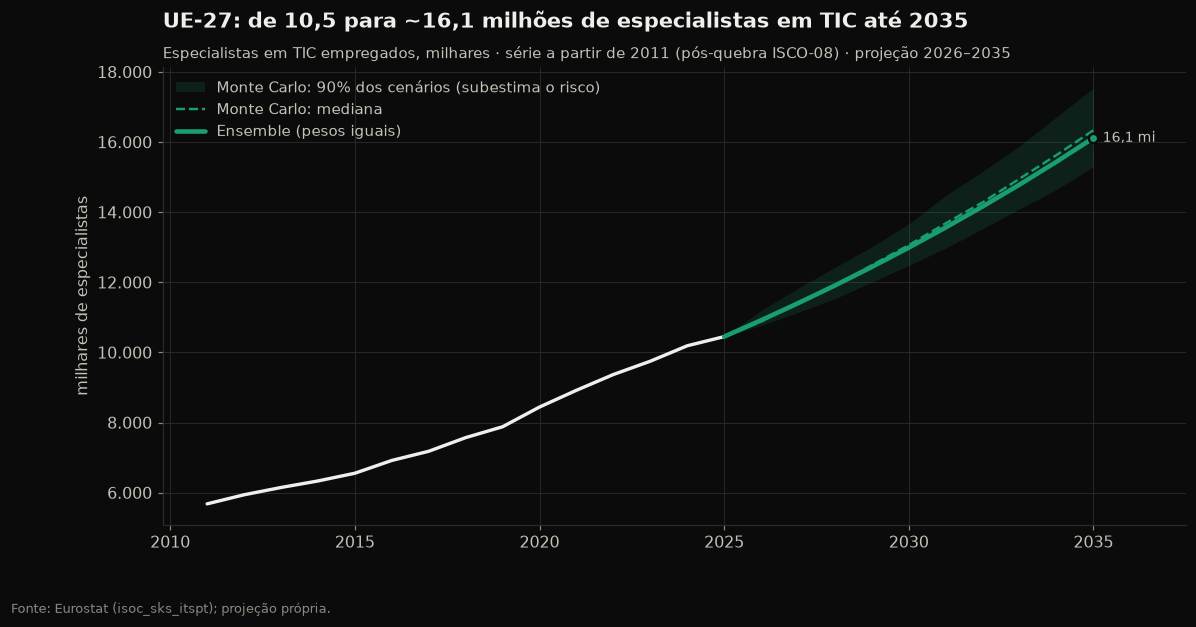

Ensemble: +54% até 2035
Modelos individuais: {'Tendência robusta (Theil-Sen 15a)': '+58%', 'ETS amortecido': '+51%', 'ARIMA com drift': '+55%'}
Monte Carlo: mediana +56% · 90%: +46% a +68% · P(2035 > 2025) = 100.0%


In [8]:
eu = ds.fetch_eurostat_ict()
eu27_full = eu[(eu.geo == "EU27_2020") & (eu.unit == "THS_PER")].set_index("time").sort_index()
print("Quebras de série (flag b):", eu27_full.index[eu27_full["flag"].str.contains("b")].tolist())
eu27 = eu27_full.loc[2011:, "value"]
eu27.index.name = "year"
ens_eu = m.equal_weight_ensemble(eu27, H)
indiv_eu = {k: f(eu27, H).iloc[-1] for k, f in m.MODELS.items() if not k.startswith("Ingênuo")}
paths_eu = m.block_bootstrap_paths(eu27, h=H, n_sims=20_000, block=3)
q_eu = paths_eu.quantile([0.05, 0.5, 0.95]).T
EU = style.color_for("UE-27")

fig, ax = plt.subplots(figsize=(12, 5.4))
ax.plot(eu27.index, eu27, color=style.TEXT_PRIMARY, lw=2.2)
xs = [eu27.index[-1], *q_eu.index]
ax.fill_between(xs, [eu27.iloc[-1], *q_eu[0.05]], [eu27.iloc[-1], *q_eu[0.95]], color=EU, alpha=0.15, lw=0,
                label="Monte Carlo: 90% dos cenários (subestima o risco)")
ax.plot(xs, [eu27.iloc[-1], *q_eu[0.5]], color=EU, lw=1.6, ls="--", label="Monte Carlo: mediana")
s = pd.concat([eu27.iloc[[-1]], ens_eu])
ax.plot(s.index, s, color=EU, lw=3, label="Ensemble (pesos iguais)")
style.label_line_end(ax, s.index[-1], s.iloc[-1], f"{style.fmt_num(s.iloc[-1] / 1000, 1)} mi", EU)
ax.legend(loc="upper left")
style.thousands_axis(ax)
ax.set_xlim(right=2037.5)
ax.set_ylabel("milhares de especialistas")
ax.set_title(f"UE-27: de {style.fmt_num(eu27.iloc[-1] / 1000, 1)} para ~{style.fmt_num(ens_eu.iloc[-1] / 1000, 1)} milhões "
             f"de especialistas em TIC até 2035")
style.subtitle(ax, "Especialistas em TIC empregados, milhares · série a partir de 2011 (pós-quebra ISCO-08) · projeção 2026–2035")
style.source(fig, "Eurostat (isoc_sks_itspt); projeção própria.")
style.save(fig, "04_06_europa_previsao")
plt.show()

fin_eu = paths_eu.iloc[:, -1] / eu27.iloc[-1] - 1
print(f"Ensemble: {(ens_eu.iloc[-1] / eu27.iloc[-1] - 1) * 100:+.0f}% até {ens_eu.index[-1]}")
print("Modelos individuais:", {k: f"{(v / eu27.iloc[-1] - 1) * 100:+.0f}%" for k, v in indiv_eu.items()})
print(f"Monte Carlo: mediana {fin_eu.median() * 100:+.0f}% · 90%: {fin_eu.quantile(0.05) * 100:+.0f}% a "
      f"{fin_eu.quantile(0.95) * 100:+.0f}% · P(2035 > {eu27.index[-1]}) = {(fin_eu > 0).mean() * 100:.1f}%")

> **Cuidado ao ler o Monte Carlo europeu:** a série pós-2011 da UE-27 **nunca registrou um ano de queda**, então o
> bootstrap não consegue gerar cenários de contração e a probabilidade de alta sai próxima de 100%. Isso não é
> certeza: é um limite do método com pouco histórico. A convergência dos três modelos (todos acima de +50%) é a
> evidência mais útil aqui.

## Conclusão da previsão

Os números abaixo vêm das células deste notebook.

- **Backtest:** o modelo "sem crescimento" subestimou o emprego tech 10 anos depois em **todas** as origens testadas.
  O ensemble reduz o erro de 10 anos para cerca de um terço do erro do ingênuo.
- **Ensemble ponderado e Monte Carlo** projetam alta do emprego no núcleo tech dos EUA até 2035, com a grande
  maioria dos cenários simulados terminando acima do nível de 2025.
- **Ritmo menor que no passado:** o ETS amortecido — que pesa mais o regime recente de queda — é o único modelo que
  projeta estagnação/queda, e por isso a faixa de incerteza é larga. O crescimento esperado é **positivo, mas mais
  moderado** que os ~4% a.a. da década de 2010.
- **O BLS, com metodologia independente, projeta as ocupações de computação e matemática crescendo +7,3% contra
  +3,5% da economia** — cerca de **2× o ritmo médio**, com ~316 mil vagas abertas por ano.
- **Europa:** os três modelos convergem para alta de mais de 50% no número de especialistas em TIC da UE-27 até 2035,
  extrapolando uma série que cresceu todos os anos desde 2012 (a incerteza real é maior que a simulada).